# Predicting a Negotiation: the Group's Center of Mass

Eleven parties have a say in a decision that can land anywhere from 0 to 100. Each party has
- a **position** P: the outcome it wants,
- an **influence** I: how much it can move the others (only the shares matter),
- a **salience** S, from 0 to 100: how much it cares about this issue compared with everything else it has to deal with.

The prediction is the group's center of mass: every position weighted by salience × influence,

$$\hat{x} = \frac{\sum_k S_k I_k P_k}{\sum_k S_k I_k}.$$

A powerful party that does not care much pulls the outcome less than a weaker one that cares a lot.

The parties and the arithmetic come from a 2009 spreadsheet, `resources/predictioneersgame.ods`. The method is
the simple expected-utility model popularized by Bruce Bueno de Mesquita, the "predictioneer". The second half
of the notebook follows the 2009 code: negotiations rarely happen all at once. Some parties settle among
themselves first and then speak as one coalition. Here every way of forming coalitions before the final
negotiation is played out, all 678,570 of them, to see how far the coalitions alone can move the outcome.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, str(Path.cwd().parent))  # project root, so negotiations imports without installing
from negotiations import example, game, model

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED = "#0b0b0b", "#6b6a66"
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#d6402a"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.axisbelow": True})

## The parties

Read directly from Sheet1 of the spreadsheet. "me" is the author, at 75. The parties were people and groups
around a small company: two directors, a customer representative, the sales staff, an engineer, an advisor, a
potential investor, legal counsel.

In [2]:
parties = example.read_spreadsheet()
parties

,position,influence,salience
party,,,
d2,15.0,20.0,80.0
customer rep,35.0,50.0,5.0
sales staff,35.0,20.0,5.0
erin,50.0,10.0,20.0
Customer 1,50.0,5.0,1.0
engineer,60.0,40.0,100.0
d1,75.0,80.0,100.0
me,75.0,80.0,100.0
advisor,100.0,80.0,20.0


## One negotiation

The spreadsheet's working, column by column: influence as a percent share, S × I, S × I × P, and the
cumulative influence counted up from the low end.

In [3]:
table = game.summary(parties)
center = game.weighted_average(parties)
majority = game.balance_of_power(parties, interpolate=False)
halfway = game.balance_of_power(parties)
print(f"weighted average (predicted outcome): {center:.2f}")
print(f"majority of influence reached at:     {majority:.0f}  (2009 code, interpolated: {halfway:.2f})")
table.round(2)

weighted average (predicted outcome): 76.60
majority of influence reached at:     75  (2009 code, interpolated: 71.48)


,position,influence,salience,influence %,S x I,S x I x P,cumulative %
party,,,,,,,
d2,15.0,20.0,80.0,3.74,299.07,4485.98,3.74
customer rep,35.0,50.0,5.0,9.35,46.73,1635.51,13.08
sales staff,35.0,20.0,5.0,3.74,18.69,654.21,16.82
erin,50.0,10.0,20.0,1.87,37.38,1869.16,18.69
Customer 1,50.0,5.0,1.0,0.93,0.93,46.73,19.63
engineer,60.0,40.0,100.0,7.48,747.66,44859.81,27.10
d1,75.0,80.0,100.0,14.95,1495.33,112149.53,42.06
me,75.0,80.0,100.0,14.95,1495.33,112149.53,57.01
advisor,100.0,80.0,20.0,14.95,299.07,29906.54,71.96


The prediction is **76.6**, just past "me" at 75. Counting influence alone, the majority is reached at 75 too:
the 2009 code finds the halfway point by spreading each position's influence back to the previous occupied
position, which puts it at 71.5. Salience is what separates the two. The three parties at 100 hold 43% of the
influence, but the advisor (salience 20) and the potential investor (5) barely care, so the outcome sits below
100. d2, alone at 15 with only 3.7% of the influence, cares a lot (80): without d2 the outcome would be 79.9, so it
pulls the prediction down by 3.3 points.

Below, each party's raw influence share (light) and its effective weight, its share of S × I (dark).

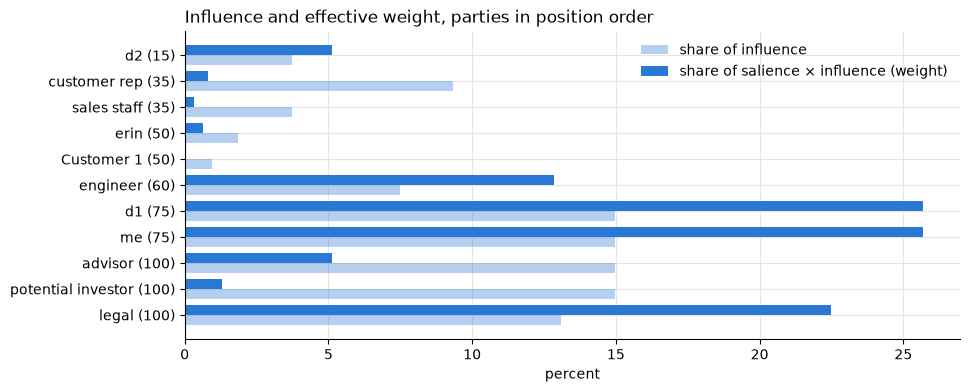

In [4]:
weight = table["S x I"] / table["S x I"].sum() * 100
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(table))
ax.barh(y + 0.2, table["influence %"], height=0.38, color=COLORS[0], alpha=0.35, label="share of influence")
ax.barh(y - 0.2, weight, height=0.38, color=COLORS[0], label="share of salience × influence (weight)")
ax.set_yticks(y, [f"{n} ({p:.0f})" for n, p in zip(table.index, table["position"])])
ax.invert_yaxis()
ax.set_xlabel("percent")
ax.set_title("Influence and effective weight, parties in position order", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.show()

The spreadsheet's chart: influence at each occupied position, and the running total that crosses half at 75.
The predicted outcome (weighted by salience) is the solid line.

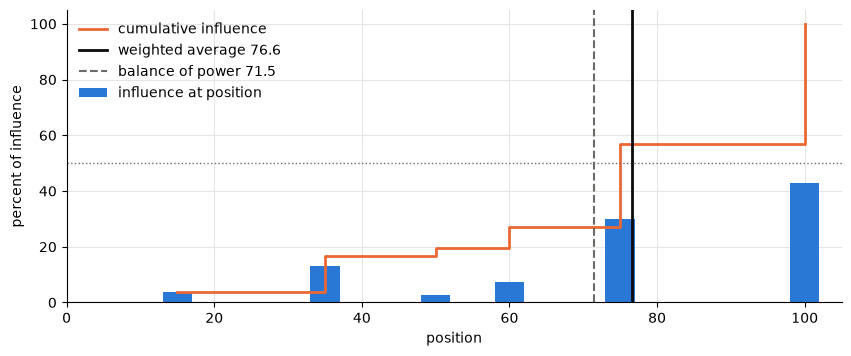

In [5]:
by_pos = table.groupby("position")[["influence %", "S x I"]].sum()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(by_pos.index, by_pos["influence %"], width=4, color=COLORS[0], label="influence at position")
ax.step(by_pos.index, by_pos["influence %"].cumsum(), where="post", color=COLORS[1], lw=2,
        label="cumulative influence")
ax.axhline(50, color=MUTED, lw=1, ls=":")
ax.axvline(center, color=INK, lw=2, label=f"weighted average {center:.1f}")
ax.axvline(halfway, color=MUTED, lw=1.5, ls="--", label=f"balance of power {halfway:.1f}")
ax.set_xlim(0, 105)
ax.set_xlabel("position")
ax.set_ylabel("percent of influence")
ax.legend(frameon=False, loc="upper left")
plt.show()

## Coalitions

Parties that settle among themselves first enter the main negotiation as one party:
- at their own weighted average position,
- with their combined influence,
- with salience 0.8 × that of the keenest member + 0.2 × the mean of the others (the 2009 rule).

If every member cares equally the coalition changes nothing: its weight is the members' combined weight at
their center of mass. The outcome moves only when saliences differ. The keen member lends its salience to
the whole coalition, so a weakly interested but influential partner suddenly counts in full, at a position
close to the keen member's.

Take d2 (position 15, salience 80) and the potential investor (100, salience 5, but 15% of the influence):

In [6]:
pair = game.coalition(parties, ["d2", "potential investor"])
display(pd.concat([parties.loc[["d2", "potential investor"]], pair]).round(2))
outcome, _ = model.succession(parties, [["d2", "potential investor"]])
print(f"outcome {center:.2f} -> {outcome:.2f}")

,position,influence,salience
party,,,
d2,15.0,20.0,80.0
potential investor,100.0,80.0,5.0
d2+potential investor,32.0,100.0,65.0


outcome 76.60 -> 70.97


The pair settles at 32, close to d2, and carries 100 influence at salience 65. Before, the investor's
80 influence counted at salience 5. One side deal moves the prediction by 5.6 points.

Every two-party coalition, and how far it moves the outcome on its own (all other parties negotiating
individually):

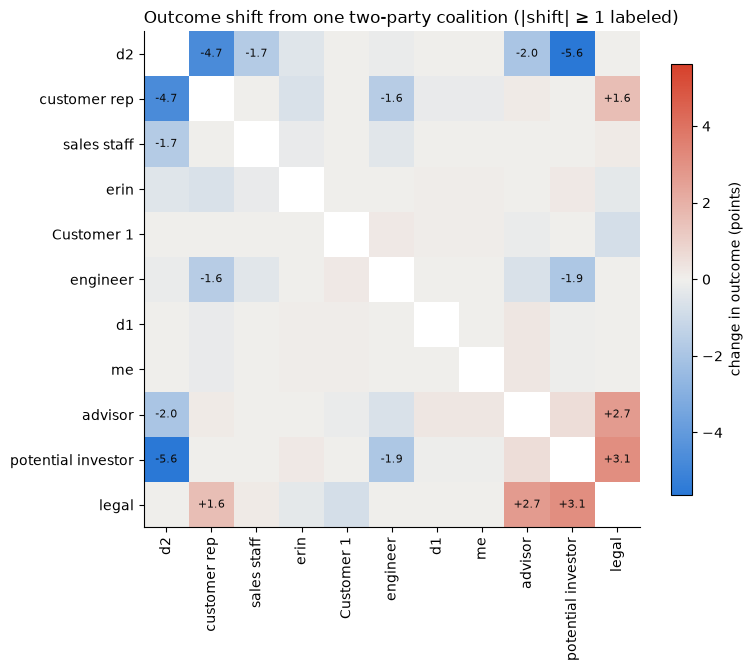

In [7]:
names = list(parties.index)
shift = pd.DataFrame(np.nan, index=names, columns=names)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        shift.loc[a, b] = shift.loc[b, a] = model.succession(parties, [[a, b]])[0] - center

lim = np.nanmax(np.abs(shift.to_numpy()))
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(shift, cmap=DIVERGING, vmin=-lim, vmax=lim)
ax.set_xticks(range(len(names)), names, rotation=90)
ax.set_yticks(range(len(names)), names)
ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        v = shift.iat[i, j]
        if abs(v) >= 1:
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="change in outcome (points)")
ax.set_title("Outcome shift from one two-party coalition (|shift| ≥ 1 labeled)", loc="left")
plt.show()

The large shifts all pair a keen party with an influential, indifferent one: d2 with the investor, the customer
rep or the advisor pulls the outcome down, legal with the investor, the advisor or the customer rep pushes it up.
Parties that care equally (d1, me, engineer, legal at 100; customer rep and sales staff at 5) can join each
other without effect.

## A succession of negotiations

Coalitions can nest: a coalition can form and then join a larger one before the final round. A plan is written
as nested lists of party names. Each list is a negotiation, and anyone not named negotiates alone in the final
round. In this one, d1 and "me" agree first and bring the engineer in, the customer side (customer rep, sales
staff, Customer 1) settles, then legal persuades the advisor and the investor:

The plan below as a diagram. Each box is one negotiation; d2 and erin are not named, so they negotiate alone in the final round.

```mermaid
flowchart LR
    d1([d1]) & me([me]) --> A["d1 + me<br/>75, salience 100"]
    A & eng([engineer]) --> B["d1 + me + engineer<br/>72, salience 100"]
    cr([customer rep]) & ss([sales staff]) & c1([Customer 1]) --> C["customer side<br/>35.2, salience 4.6"]
    lg([legal]) & adv([advisor]) & inv([potential investor]) --> L["legal + advisor + investor<br/>100, salience 82.5"]
    B & C & L & d2([d2]) & erin([erin]) --> F{{"final round<br/>82.3"}}
    class d1,me,eng,cr,ss,c1,lg,adv,inv,d2,erin data
    class A,B,C,L step
    class F good
    classDef data fill:#e8f1fb,stroke:#3b6ea8,color:#1d3557
    classDef step fill:#f4f4f5,stroke:#71717a,color:#18181b
    classDef choice fill:#fff4e0,stroke:#c77d0a,color:#5c3a00
    classDef good fill:#e6f4ea,stroke:#2f855a,color:#1c4532
    classDef bad fill:#fdecea,stroke:#c0392b,color:#611a15
    classDef hidden fill:#f4f4f5,stroke:#71717a,color:#3f3f46,stroke-dasharray:5 4
    classDef group fill:transparent,stroke:#a1a1aa,stroke-dasharray:4 3
```

In [8]:
plan = [
    [["d1", "me"], "engineer"],
    ["customer rep", "sales staff", "Customer 1"],
    ["legal", "advisor", "potential investor"],
]
outcome, steps = model.succession(parties, plan)
steps.assign(parties=steps["parties"].map(", ".join)).round(2)

,parties,position,influence,salience
0,"d1, me",75.00,160.0,100.00
1,"d1+me, engineer",72.00,200.0,100.00
2,"customer rep, sales staff, Customer 1",35.21,75.0,4.60
3,"legal, advisor, potential investor",100.00,230.0,82.50
4,"d1+me+engineer, customer rep+sales staff+Custo...",82.29,535.0,89.36


In [9]:
print(f"single negotiation {center:.2f}, after this succession {outcome:.2f}")

single negotiation 76.60, after this succession 82.29


The legal-led coalition lends legal's salience to the advisor and the investor, and their weight at 100 moves
the outcome up by 5.7 points, to 82.3.

## Every coalition structure

How much can the choice of coalitions alone move the outcome? A coalition structure is a way of splitting the
11 parties into groups. Each group settles, then the groups negotiate. The number of structures is the Bell
number B(11) = 678,570. All of them are computed at once (the 2009 code played them out one by one).

In [10]:
%time structures = model.all_structures(parties)
outcomes = pd.Series(structures.outcome)
outcomes.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2)

CPU times: user 262 ms, sys: 130 ms, total: 392 ms
Wall time: 392 ms


count    678570.00
mean         75.83
std           2.39
min          65.95
5%           71.27
25%          74.60
50%          76.19
75%          77.21
95%          79.41
max          83.83
dtype: float64

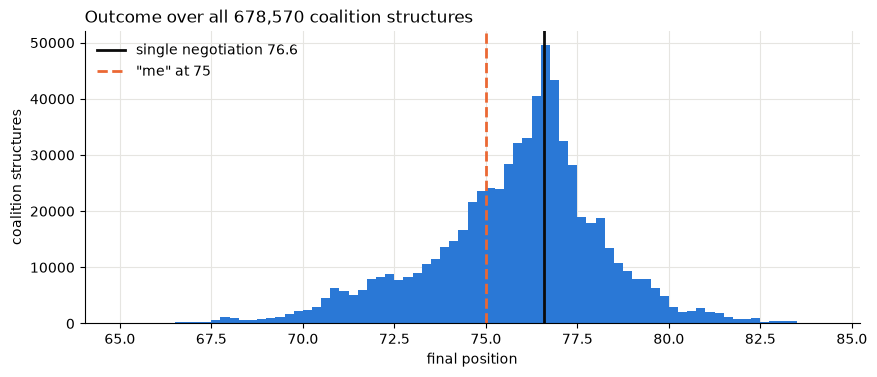

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(structures.outcome, bins=np.arange(65, 84.5, 0.25), color=COLORS[0])
ax.axvline(center, color=INK, lw=2, label=f"single negotiation {center:.1f}")
ax.axvline(75, color=COLORS[1], lw=2, ls="--", label='"me" at 75')
ax.set_xlabel("final position")
ax.set_ylabel("coalition structures")
ax.set_title(f"Outcome over all {len(outcomes):,} coalition structures", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.show()

Half of all structures land between 74.6 and 77.2, and 90% between 71.3 and 79.4. The full range is
66 to 84, so coalitions can move the outcome by as much as 10 points.

By the number of coalitions: one coalition of everybody and eleven parties alone are the same single
negotiation (76.6). In between, the typical outcome dips slightly and the range is widest at four to six
coalitions.

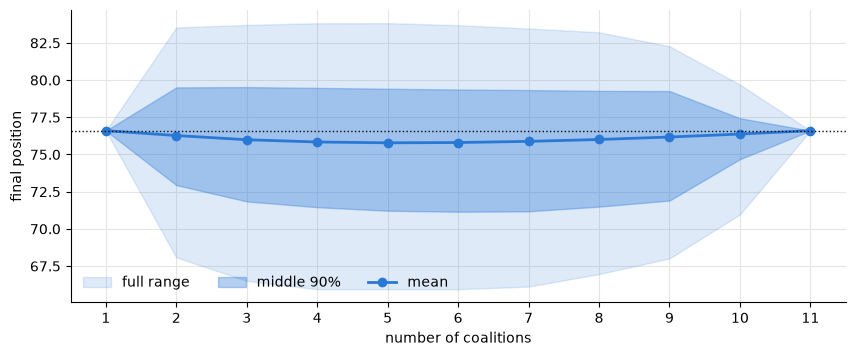

,count,mean,min,max
1,1.0,76.60,76.60,76.60
2,1023.0,76.27,68.09,83.54
3,28501.0,75.99,66.51,83.71
4,145750.0,75.84,65.95,83.82
5,246730.0,75.79,65.95,83.83
6,179487.0,75.80,65.95,83.69
7,63987.0,75.88,66.12,83.47
8,11880.0,76.01,66.96,83.21
9,1155.0,76.18,68.01,82.28
10,55.0,76.37,70.97,79.70


In [12]:
by_count = outcomes.groupby(structures.coalitions).describe(percentiles=[0.05, 0.95])
fig, ax = plt.subplots(figsize=(10, 3.8))
k = by_count.index
ax.fill_between(k, by_count["min"], by_count["max"], color=COLORS[0], alpha=0.15, label="full range")
ax.fill_between(k, by_count["5%"], by_count["95%"], color=COLORS[0], alpha=0.35, label="middle 90%")
ax.plot(k, by_count["mean"], "o-", color=COLORS[0], lw=2, ms=6, label="mean")
ax.axhline(center, color=INK, lw=1, ls=":")
ax.set_xticks(k)
ax.set_xlabel("number of coalitions")
ax.set_ylabel("final position")
ax.legend(frameon=False, loc="lower left", ncol=3)
plt.show()
by_count[["count", "mean", "min", "max"]].round(2)

The structures with the lowest and highest outcomes:

In [13]:
order = np.argsort(structures.outcome)
extremes = [(k, structures.outcome[k], structures.describe(k)) for k in [*order[:3], *order[-3:]]]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(extremes, columns=["structure", "outcome", "coalitions"]).set_index("structure").round(2))

,outcome,coalitions
structure,,
3175,65.95,d2+customer rep+sales staff+erin+potential investor | Customer 1+legal | engineer+d1+me | advisor
3305,65.95,d2+customer rep+sales staff+erin+potential investor | Customer 1+legal | engineer+d1 | me | advisor
3869,65.95,d2+customer rep+sales staff+erin+potential investor | Customer 1+legal | engineer | d1+me | advisor
293179,83.82,d2 | customer rep+sales staff+advisor+potential investor+legal | erin+me | Customer 1+engineer+d1
300338,83.83,d2 | customer rep+sales staff+advisor+potential investor+legal | erin+me | Customer 1+d1 | engineer
299033,83.83,d2 | customer rep+sales staff+advisor+potential investor+legal | erin+d1 | Customer 1+me | engineer


The low end (65.9): d2 recruits the customer rep, the sales staff, erin and the potential investor, legal has only
Customer 1, and the advisor stays alone. Whether the engineer, d1 and "me" join each other makes no difference,
since they all have salience 100. The high end (83.8): the customer rep, sales staff, advisor and investor all
join legal, and d2 is left alone.

## Who to be in a coalition with

Mean outcome over the structures in which each pair of parties is in the same coalition, compared with the mean
over all structures (75.8). The diagonal: the structures in which the party negotiates alone.

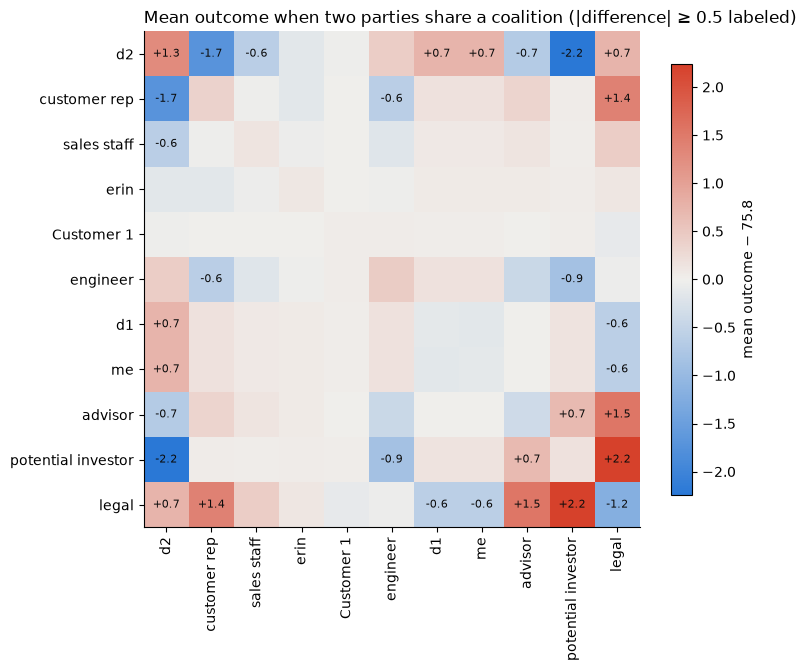

In [14]:
pair_means = structures.pair_means() - outcomes.mean()
lim = np.abs(pair_means.to_numpy()).max()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(pair_means, cmap=DIVERGING, vmin=-lim, vmax=lim)
ax.set_xticks(range(len(names)), names, rotation=90)
ax.set_yticks(range(len(names)), names)
ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        v = pair_means.iat[i, j]
        if abs(v) >= 0.5:
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label=f"mean outcome − {outcomes.mean():.1f}")
ax.set_title("Mean outcome when two parties share a coalition (|difference| ≥ 0.5 labeled)", loc="left")
plt.show()

Averaged over everything else that can happen, the same pattern holds. Who the indifferent parties (the
investor, the customer rep, the advisor) end up with matters most. With d2 they lower the mean outcome by up to
2.2 points, with legal they raise it by 1.4 to 2.2. When legal stays out of every coalition the outcome is 1.2
points lower, and when d2 does it is 1.3 points higher.

For "me", the outcome barely depends on whom "me" joins (75.2 to 76.6). The parties at 75 already sit near the
center of mass, so what they do changes little. What moves the result is where the influential, indifferent
parties go.

## Notes

- The package reproduces the 2009 code (`MultiPlayerGame.py`, `MultiPlayerNegotiationsModel.py`) run under
  Python 3: the same weighted average and interpolated balance of power, and the same final position for every one
  of the 678,570 structures (to 1e-13). The tests check samples of those values.
- Positions are taken as given on 0 to 100. The 2009 class rescaled them by the largest position when called
  without `maxPos`, which leaves this example unchanged.
- The coalition salience rule (0.8 × the keenest + 0.2 × the rest) is the one modeling choice that makes
  coalitions matter. `negotiations.game.OTHERS_WEIGHT` sets the 0.2. With a plain average of the members'
  saliences the coalition effects shrink but do not vanish: the d2 + investor coalition moves the outcome by
  −3.0 points instead of −5.6.